This dataset include players both skaters and goalies who are inactive from last 3 years to satisfy eligibility criteria for hof.

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [74]:
# Read Dataset
players = pd.read_csv("/Users/arpitagonnade/Arpita_study_materials/Data Mining/Python_practise/DATS6103-final-project/Dataset/Merged_data.csv")
players.shape

(7304, 15)

In [75]:
players.isna().sum()

name           0
first          0
last           0
position       0
games          0
goals          0
assists        0
time        3566
active         0
hof            0
started     7100
wins        6577
losses      6577
conceded    6575
saves       6663
dtype: int64

### Cleaning data

1) Consider players whose career ended after 1998, due to many missing values

In [76]:
players = players[players["last"]> 1998]
players.shape

(3249, 15)

In [77]:
players.isna().sum()

name           0
first          0
last           0
position       0
games          0
goals          0
assists        0
time           0
active         0
hof            0
started     3045
wins        2922
losses      2922
conceded    2920
saves       2920
dtype: int64

In [78]:
players["active"].value_counts()

active
False    3249
Name: count, dtype: int64

Since all the players are inactive which is a condition for eligibility of hall of fame. Thus, dropping column "active" from the dataset.

In [79]:
players = players.drop(columns=["active"])

### Feature Engineering

1) career_duration = Last season − First season + 1
2) games_per_season = games/career_duration
3) assists_per_game = assists/games

In [80]:
players["career_duration"] = players["last"] - players["first"] + 1
players["games_per_season"] = players["games"]/players["career_duration"]
players["assists_per_game"] = players["assists"] /players["games"]

In [81]:
players.head()

,name,first,last,position,games,goals,assists,time,hof,started,wins,losses,conceded,saves,career_duration,games_per_season,assists_per_game
0,Antti Aalto,1998,2001,C,151,11,17,1668.0,False,NaN,NaN,NaN,NaN,NaN,4,37.750000,0.112583
2,Spencer Abbott,2014,2017,LW,2,0,0,14.0,False,NaN,NaN,NaN,NaN,NaN,4,0.500000,0.000000
3,Justin Abdelkader,2008,2020,LW,739,106,146,11010.0,False,NaN,NaN,NaN,NaN,NaN,13,56.846154,0.197564
7,Pontus Åberg,2017,2020,LW,132,17,27,1734.0,False,NaN,NaN,NaN,NaN,NaN,4,33.000000,0.204545
9,Ramzi Abid,2003,2007,LW,68,14,16,825.0,False,NaN,NaN,NaN,NaN,NaN,5,13.600000,0.235294


## VISUALIZATION

In [82]:
hof_counts = players["hof"].value_counts()
hof_percentages = hof_counts / hof_counts.sum() * 100

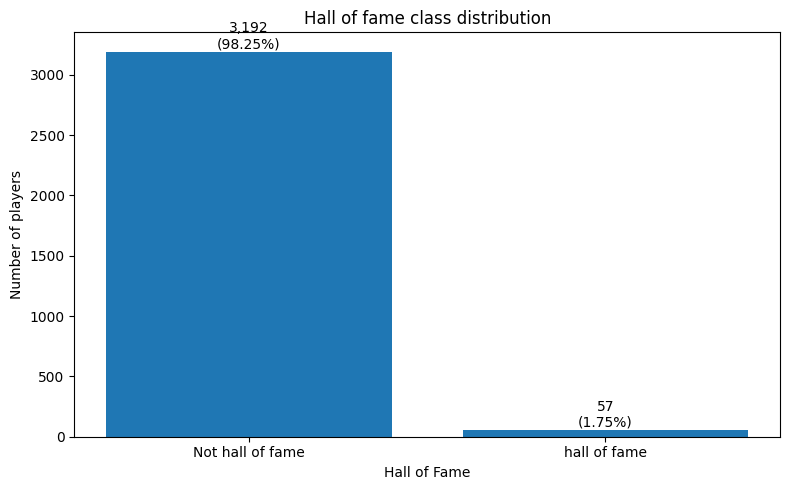

In [83]:
labels = ["Not hall of fame", "hall of fame"]
fig , ax = plt.subplots(figsize = (8,5))

bars = ax.bar(
    labels,
    hof_counts.values
)
ax.set_title("Hall of fame class distribution")
ax.set_xlabel("Hall of Fame")
ax.set_ylabel("Number of players")

for bar, count, pct in zip(bars, hof_counts.values, hof_percentages.values):
    ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{count:,}\n({pct:.2f}%)",
            ha="center",
            va="bottom"
        )

plt.tight_layout()
plt.show()

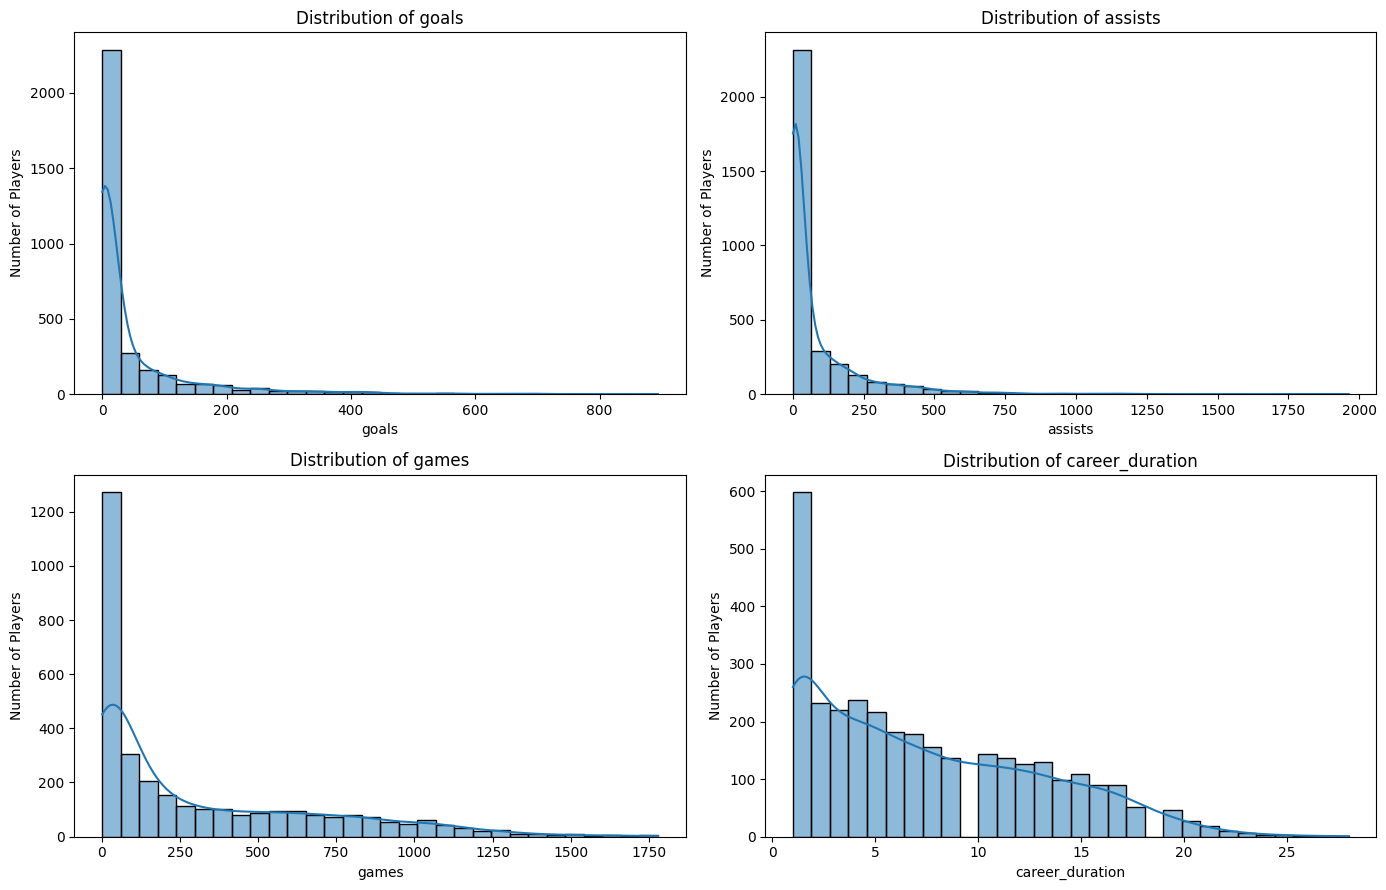

In [87]:
# Skewness of data

features_to_plot = [
    "goals",
    "assists",
    "games",
    "career_duration"
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(14, 9)
)

for ax, col in zip(axes.flatten(), features_to_plot):

    sns.histplot(
        data=players,
        x=col,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Players")

plt.tight_layout()
plt.show()

#### Interpretation:

Games : most players have fewer games played and a small number have very high totals, this indicates that career opportunities vary considerably.

career_distribution : most players have relatively short careers while a smaller group plays for many seasons.

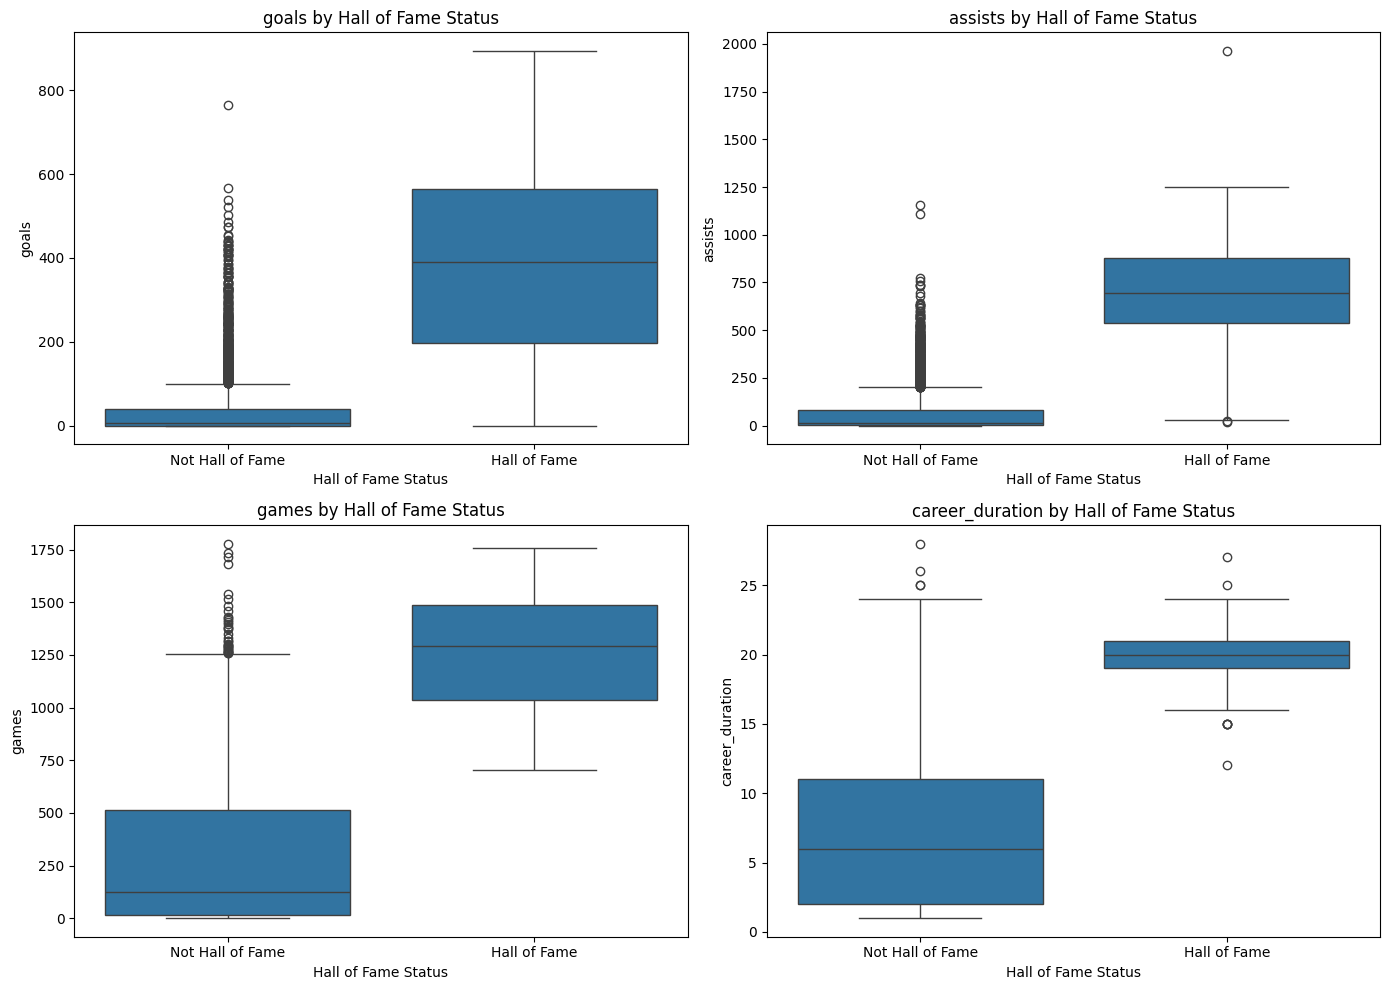

In [89]:
box_features = features_to_plot

plot_df = players.dropna(
    subset=["hof"] + box_features
).copy()

plot_df["hof_label"] = plot_df["hof"].map({
    0: "Not Hall of Fame",
    1: "Hall of Fame"
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

for ax, col in zip(axes.flatten(), box_features):

    sns.boxplot(
        data=plot_df,
        x="hof_label",
        y=col,
        ax=ax
    )

    ax.set_title(f"{col} by Hall of Fame Status")
    ax.set_xlabel("Hall of Fame Status")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

#### Interpretation:

1. Median differences

If the Hall of Fame group's median goals are higher than the non-Hall of Fame group's median, inductees tend to have higher career goal totals in this sample.

2. Spread

If the Hall of Fame group's box is wider, its middle 50% of values are more dispersed.

3. Overlap

If the two groups overlap substantially, that statistic alone may not clearly distinguish Hall of Fame players from non-inductees.

4. Outliers

If some players have extremely high career goals, they may appear as individual points beyond the whiskers.

Outliers are not necessarily errors. A player with an exceptionally long career may legitimately have a very high goal total.

Association between features

In [84]:
players.dtypes

name                 object
first                 int64
last                  int64
position             object
games                 int64
goals                 int64
assists               int64
time                float64
hof                    bool
started             float64
wins                float64
losses              float64
conceded            float64
saves               float64
career_duration       int64
games_per_season    float64
assists_per_game    float64
dtype: object

In [85]:
players['hof'] = players['hof'].astype('int')


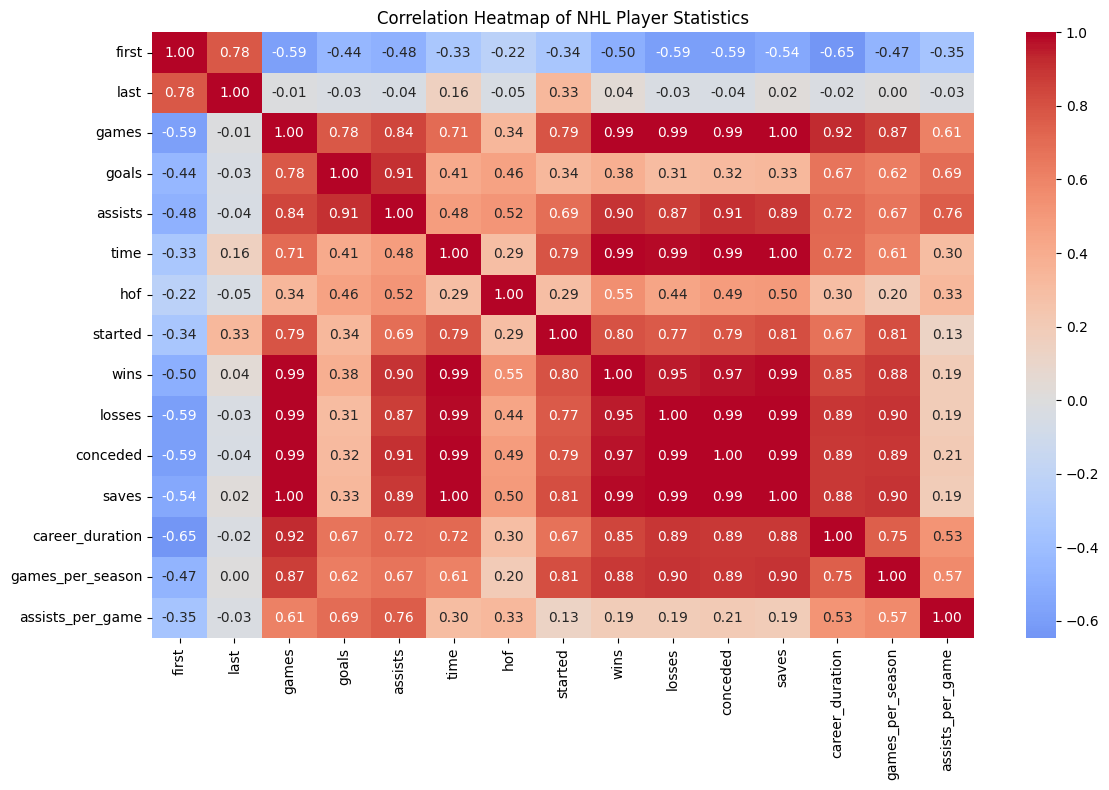

In [86]:
# visiualization - heat map to show association
# Select numerical columns
numeric_df = players.select_dtypes(include="number")
numeric_df
# Calculate correlations
corr = numeric_df.corr()
# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of NHL Player Statistics")
plt.tight_layout()